## 1. Packages

In [467]:
# basic package
import pandas as pd
import numpy as np

In [545]:
# use scikit-learn for the classification algorithms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline




In [537]:
# for representation
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

# for evaluation
from sklearn.pipeline import Pipeline
from sklearn import metrics
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

In [15]:
# for tokenize
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/lifangjing/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/lifangjing/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 2. Corpus

In [17]:
# read in data
trainingdata = pd.read_csv('train.txt', sep='\t', names=['pmid', 'label', 'text'])
testdata = pd.read_csv('test.txt', sep='\t', names=['pmid', 'label', 'text'])
devdata = pd.read_csv('dev.txt', sep='\t', names=['pmid', 'label', 'text'])

In [19]:
trainingdata.head(10)

,pmid,label,text
0,24293578,OBJECTIVE,To investigate the efficacy of 6 weeks of dail...
1,24293578,METHODS,A total of 125 patients with primary knee OA w...
2,24293578,METHODS,Outcome measures included pain reduction and i...
3,24293578,METHODS,Pain was assessed using the visual analog pain...
4,24293578,METHODS,Secondary outcome measures included the Wester...
5,24293578,METHODS,"Serum levels of interleukin 1 ( IL-1 ) , IL-6 ..."
6,24293578,RESULTS,There was a clinically relevant reduction in t...
7,24293578,RESULTS,The mean difference between treatment arms ( 9...
8,24293578,RESULTS,"Further , there was a clinically relevant redu..."
9,24293578,RESULTS,These differences remained significant at 12 w...


In [20]:
trainingdata['text'][0]

'To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .'

In [36]:
# to see the label distribution
trainingdata['label'].value_counts()

label
METHODS        59353
RESULTS        57953
CONCLUSIONS    27168
BACKGROUND     21727
OBJECTIVE      13839
Name: count, dtype: int64

In [197]:
# test data label distribution
testdata['label'].value_counts()

label
METHODS        9897
RESULTS        9713
CONCLUSIONS    4571
BACKGROUND     3621
OBJECTIVE      2333
Name: count, dtype: int64

Subset strategy

The dataset is too large so I would use the subset

I choose the dataset based on the original distribution of abstract lengths 

Because sentences are related from one abstract and different lengths of abstract show different organization way in sentences

In [23]:
# number of pmid, meaning sentences number of one abstact
pmid_counts = trainingdata['pmid'].value_counts()

In [476]:
# distribution of abstact length
count_of_counts = pmid_counts.value_counts().sort_index()
count_of_counts

count
4        8
5       43
6      191
7      479
8      933
9     1365
10    1940
11    2149
12    2039
13    1701
14    1317
15     974
16     673
17     437
18     289
19     176
20     124
21      61
22      35
23      33
24      11
25       8
26       7
27       3
28       1
29       2
31       1
Name: count, dtype: int64

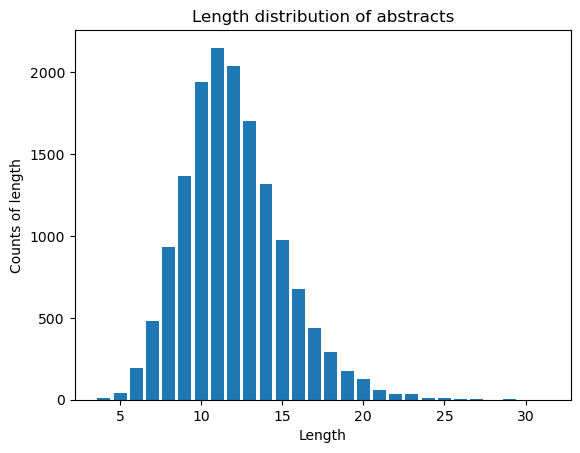

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# plot the distribution
plt.bar(count_of_counts.index, count_of_counts.values)
plt.xlabel('Length')
plt.ylabel('Counts of length')
plt.title('Length distribution of abstracts')
plt.show()

# it's skewed

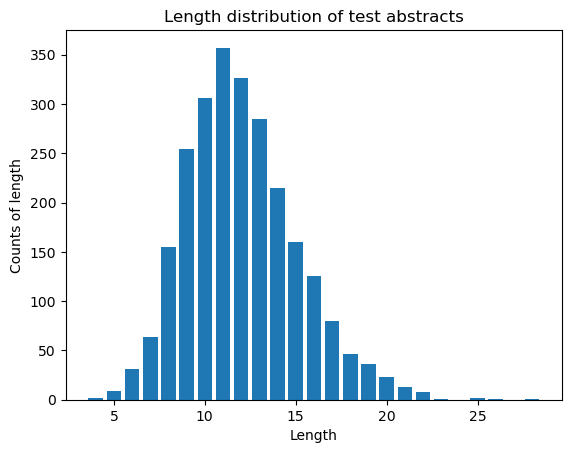

In [482]:
# same for test and plotting
pmid_counts_test = testdata['pmid'].value_counts()
count_of_counts_test = pmid_counts_test.value_counts().sort_index()

plt.bar(count_of_counts_test.index, count_of_counts_test.values)
plt.xlabel('Length')
plt.ylabel('Counts of length')
plt.title('Length distribution of test abstracts')
plt.show()

# the distribution is quite similar to the training set
# also skewed

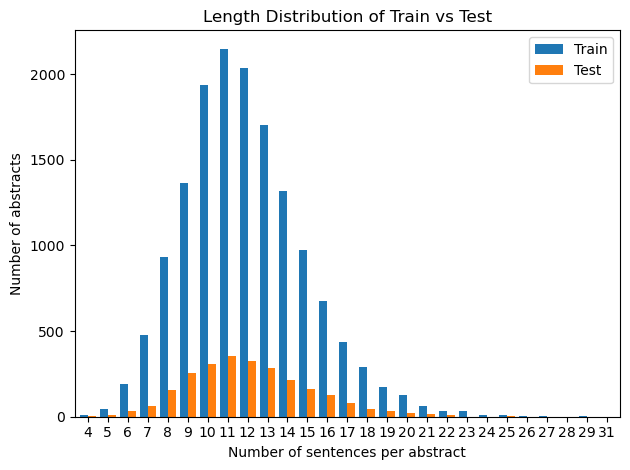

In [480]:
# put them together to see the difference of distribution
train_len = trainingdata['pmid'].value_counts().value_counts().sort_index()
test_len = testdata['pmid'].value_counts().value_counts().sort_index()

df = (
    pd.DataFrame({'Train': train_len, 'Test': test_len})
    .fillna(0) 
    .astype(int)
)

# plotting
df.plot(kind='bar', width=0.8)

plt.xlabel("Number of sentences per abstract")
plt.ylabel("Number of abstracts")
plt.title("Length Distribution of Train vs Test")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# actually the distributions are different to some extent
# train set has a higher density in the middle range
# a large number of abstracts had a moderate number of sentences, while fewer abstracts are extremely short or long.
# subset sampling will more likely to select abstracts from this dense middle range

In [169]:
from collections import defaultdict

# mapping from abstract length to a list of pmids
length_to_pmids1 = defaultdict(list)
length_to_pmids2 = defaultdict(list)

# for training set
for pmid, count in pmid_counts.items():
    length_to_pmids1[count].append(pmid)

# for test set
for pmid, count in pmid_counts_test.items():
    length_to_pmids2[count].append(pmid)


In [504]:
# define a sampling function based on the distribution of abstract lengths from the original dataset
def stratified_sample_pmids(length_to_pmids, target_total, seed=42):
    random.seed(seed)
    sampled_pmids = []
    all_pmids_used = set()
    
    # total number of abstracts
    total_abstracts = sum(len(pmids) for pmids in length_to_pmids.values())

    # for each abstract length group, sample pmids by proportion
    for length, pmids in length_to_pmids.items():
        proportion = len(pmids) / total_abstracts # calculate proportion
        sample_size = round(proportion * target_total)
        available = list(set(pmids) - all_pmids_used) # avoid duplicate sampling
        sample_size = min(sample_size, len(available))
        sampled = random.sample(available, sample_size) # sample pmids from this group
        sampled_pmids.extend(sampled)
        all_pmids_used.update(sampled)

    # if the total sample is below target_total, randomly fill in
    remaining = target_total - len(sampled_pmids)
    if remaining > 0:
        all_pmids_flat = [pmid for pmids in length_to_pmids.values() for pmid in pmids]
        unused = list(set(all_pmids_flat) - set(sampled_pmids))
        sampled_pmids.extend(random.sample(unused, remaining))

    # return pmids we choosed
    return sampled_pmids


In [512]:
# for training sample
sampled_pmids = stratified_sample_pmids(length_to_pmids, target_total=5000)

# for test sample
sampled_pmids2 = stratified_sample_pmids(length_to_pmids2, target_total=1000)

In [514]:
# get subset
train_subset = trainingdata[trainingdata['pmid'].isin(sampled_pmids)]
test_subset = testdata[testdata['pmid'].isin(sampled_pmids2)]

In [518]:
train_subset['label'].value_counts()

label
METHODS        19849
RESULTS        19373
CONCLUSIONS     9003
BACKGROUND      7223
OBJECTIVE       4570
Name: count, dtype: int64

In [520]:
test_subset['label'].value_counts()

label
METHODS        3967
RESULTS        3876
CONCLUSIONS    1843
BACKGROUND     1437
OBJECTIVE       899
Name: count, dtype: int64

In [522]:
train_subset['pmid'].value_counts().value_counts().sort_index()

count
4       3
5      14
6      64
7     160
8     311
9     455
10    647
11    716
12    680
13    567
14    439
15    325
16    224
17    146
18     96
19     59
20     41
21     20
22     12
23     11
24      4
25      3
26      2
27      1
29      1
Name: count, dtype: int64

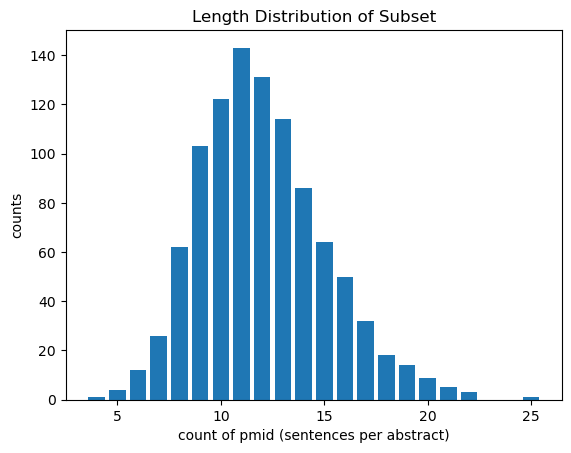

In [528]:
# plot the distribution of subset
subset_counts = train_subset['pmid'].value_counts()
subset_count_of_counts = subset_counts.value_counts().sort_index()


plt.bar(subset_count_of_counts2.index, subset_count_of_counts2.values)
plt.xlabel("count of pmid (sentences per abstract)")
plt.ylabel("counts")
plt.title("Length Distribution of Subset")
plt.show()


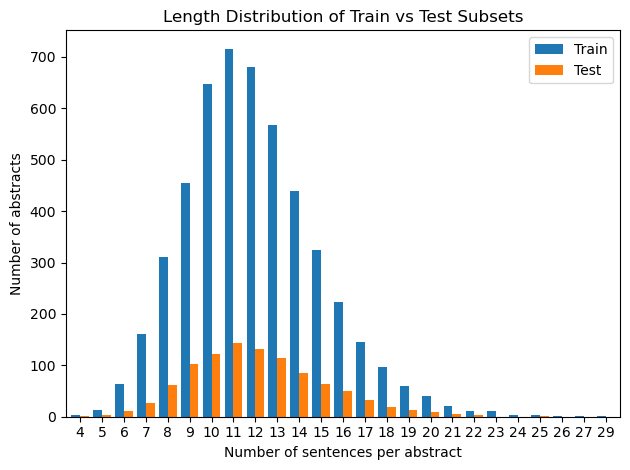

In [526]:
# plot the distribution of two subsets together
train_len = train_subset['pmid'].value_counts().value_counts().sort_index()
test_len = test_subset['pmid'].value_counts().value_counts().sort_index()

# same as before
df = (
    pd.DataFrame({'Train': train_len, 'Test': test_len})
    .fillna(0)  # 缺失补 0
    .astype(int)
)

# plotting
df.plot(kind='bar', width=0.8)

plt.xlabel("Number of sentences per abstract")
plt.ylabel("Number of abstracts")
plt.title("Length Distribution of Train vs Test Subsets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# it's almost the same as the original dataset distribution

### Machine learning

check all variations by pipeline including different representations and ml models

representations : bow tfidf
models : svm, logistic regression, random forest, kneighberhood

note : trials of generalising things like numbers failed

#### BoW representaion strategy test

In [535]:
import re # for regular expression

In [125]:
# for generalising numbers and some clean trials like excluding punctuations
def clean_text(text):
    text = text.lower()
    text = re.sub(r'\d+(\.\d+)?%?', ' <NUM> ', text)  # all numbers are replaced by <NUM>
    text = re.sub(r'[^\w\s<>]', '', text)           # exclude punctuations but keep <> in <NUM> 
    return text

In [293]:
# try not exclude punctuations
def clean_text2(text):
    text = text.lower() 
    text = re.sub(r'\d+(\.\d+)?%?', ' <NUM> ', text)
    return text

In [315]:
# try only change the numbers
def clean_text3(text):
    text = re.sub(r'\d+(\.\d+)?', ' <NUM> ', text)  
    return text

In [127]:
# nltk will split <NUM> so deal with it isolately
def smart_tokenizer(text):
    tokens = []
    for word in text.split():
        if word == "<NUM>":
            tokens.append("<NUM>")
        else:
            tokens.extend(word_tokenize(word)) 
    return tokens

In [129]:
# a test
print(clean_text("The dose was 50mg, and 60% responded."))

the dose was  <NUM> mg and  <NUM>  responded


In [139]:
# another test
tokens = smart_tokenizer(clean_text("The dose was 50mg, and 60% responded."))
print(tokens)

['the', 'dose', 'was', '<NUM>', 'mg', 'and', '<NUM>', 'responded']


In [253]:
# first representation strategy
first_vectorizer = CountVectorizer(ngram_range=(1,1), preprocessor=clean_text, stop_words='english',
                             tokenizer=smart_tokenizer, max_features=500)
# just copied from practicals
first_vectorizer.fit(subset_df['text'].tolist())
first_fit_transformed_data = first_vectorizer.fit_transform(subset_df['text']) 

/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [255]:
first_vectorizer.vocabulary_

{'evaluate': 157,
 'performance': 322,
 'efficacy': 150,
 'safety': 398,
 'new': 298,
 'compared': 87,
 'local': 253,
 'management': 264,
 'stage': 429,
 'randomised': 360,
 'controlled': 101,
 'clinical': 76,
 'trial': 472,
 'conducted': 96,
 '<NUM>': 1,
 'patients': 317,
 'baseline': 48,
 'followed': 176,
 'week': 493,
 'period': 324,
 'assessed': 38,
 'weekly': 494,
 'primary': 342,
 'criteria': 105,
 'relative': 383,
 'regression': 381,
 'area': 33,
 'treatment': 470,
 'secondary': 408,
 'endpoints': 154,
 'reduction': 378,
 'tissue': 466,
 'percentage': 321,
 'test': 457,
 'group': 190,
 'n': 294,
 'control': 100,
 'regarding': 379,
 'factors': 170,
 'duration': 143,
 'value': 483,
 'recurrence': 374,
 'groups': 191,
 'patient': 316,
 'characteristics': 70,
 'therapy': 463,
 'administered': 14,
 'median': 271,
 'day': 112,
 'similar': 419,
 'vs': 492,
 'respectively': 389,
 'significantly': 418,
 'higher': 200,
 'p': 312,
 'showed': 415,
 'better': 51,
 'therapeutic': 462,
 'curre

In [309]:
# different clean text strategy
first_vectorizer = CountVectorizer(ngram_range=(1,1), preprocessor=clean_text, stop_words='english',
                             tokenizer=smart_tokenizer, max_features=500)
first_vectorizer2 = CountVectorizer(ngram_range=(1,1), preprocessor=clean_text2, stop_words='english',
                             tokenizer=smart_tokenizer, max_features=500)
first_vectorizer3 = CountVectorizer(ngram_range=(1,1), preprocessor=clean_text3, stop_words='english',
                             tokenizer=smart_tokenizer, max_features=500)

In [259]:
# for train and test trials
X_train = first_vectorizer.fit_transform(train_subset["text"])
y_train = train_subset["label"]

X_test = first_vectorizer.transform(test_subset["text"])
y_test = test_subset["label"]

/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [539]:
# model test
lg = LogisticRegression(max_iter=2000)
lg.fit(X_train, y_train)

LogisticRegression(max_iter=2000)

In [561]:
# print performance
y_pred = lg.predict(X_test)

print("Accuracy", accuracy_score(y_test, y_pred))
print("Report\n", classification_report(y_test, y_pred))

Accuracy 0.7048743969389453
Report
               precision    recall  f1-score   support

  BACKGROUND       0.50      0.45      0.47      1437
 CONCLUSIONS       0.59      0.56      0.57      1843
     METHODS       0.74      0.84      0.79      3967
   OBJECTIVE       0.61      0.46      0.52       899
     RESULTS       0.80      0.78      0.79      3876

    accuracy                           0.70     12022
   macro avg       0.65      0.62      0.63     12022
weighted avg       0.70      0.70      0.70     12022



In [269]:
# another test
kneighbour_classifier = KNeighborsClassifier().fit(X_train, y_train)

In [543]:
# results
y_pred = kneighbour_classifier.predict(X_test)

print("Accuracy：", accuracy_score(y_test, y_pred))
print("\nReport\n", classification_report(y_test, y_pred))

Accuracy： 0.5672932956246881

Report
               precision    recall  f1-score   support

  BACKGROUND       0.32      0.49      0.39      1437
 CONCLUSIONS       0.42      0.31      0.35      1843
     METHODS       0.63      0.66      0.64      3967
   OBJECTIVE       0.43      0.13      0.20       899
     RESULTS       0.70      0.73      0.71      3876

    accuracy                           0.57     12022
   macro avg       0.50      0.46      0.46     12022
weighted avg       0.57      0.57      0.56     12022



### More representations and models

test by pipeline

In [568]:
# models dictionary
MODEL_DICT = {
    'lg': LogisticRegression(max_iter=1000),
    'kn': KNeighborsClassifier(),
    'svm': LinearSVC(),
    'rf': RandomForestClassifier(n_estimators=100, random_state=42)
}

# representation dictionary
VECTORIZER_DICT = {
    'bow': CountVectorizer(ngram_range=(1,1), stop_words=None,tokenizer=word_tokenize, max_features=500),
    'tfidf': TfidfVectorizer(tokenizer=word_tokenize, stop_words='english'),
    'mybow':first_vectorizer,
    'mybow2':first_vectorizer2,
    'mybow3':first_vectorizer3,
}

# all representations were tested
# cells after will be a bit long but without much information

In [570]:
import seaborn as sns
# build a function for total training from model training to evaluation
def run_pipeline(train_df, test_df, model='lg', vector='tfidf',cv=None):
    assert model in MODEL_DICT
    assert vector in VECTORIZER_DICT

    print(f"Using model: {model}, vectorizer: {vector}")
    #training pipeline
    pipeline = Pipeline([
        ('vectorizer', VECTORIZER_DICT[vector]),
        ('classifier', MODEL_DICT[model])
    ])

    # dataset
    X_train, y_train = train_df['text'], train_df['label']
    X_test, y_test = test_df['text'], test_df['label']

    if cv:  # cross-validation way
        print(f"Running {cv}-fold cross validation...")
        f1_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='f1_macro')
        acc_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')

        print("F1 macro scores:", f1_scores)
        print("Mean F1:", f1_scores.mean())

        print("Accuracy scores:", acc_scores)
        print("Mean accuracy:", acc_scores.mean())
        return
        
    # train by pipeline
    pipeline.fit(X_train, y_train)

    # prediction
    y_pred = pipeline.predict(X_test)

    # print results
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\n Classification Report:\n")
    print(classification_report(y_test, y_pred))

    # confusion matrix
    labels = sorted(set(y_test))
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion Matrix ({model.upper()}, {vector.upper()})")
    plt.tight_layout()
    plt.show()

    return pipeline


Using model: lg, vectorizer: mybow


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Accuracy: 0.7048743969389453

 Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.50      0.45      0.47      1437
 CONCLUSIONS       0.59      0.56      0.57      1843
     METHODS       0.74      0.84      0.79      3967
   OBJECTIVE       0.61      0.46      0.52       899
     RESULTS       0.80      0.78      0.79      3876

    accuracy                           0.70     12022
   macro avg       0.65      0.62      0.63     12022
weighted avg       0.70      0.70      0.70     12022



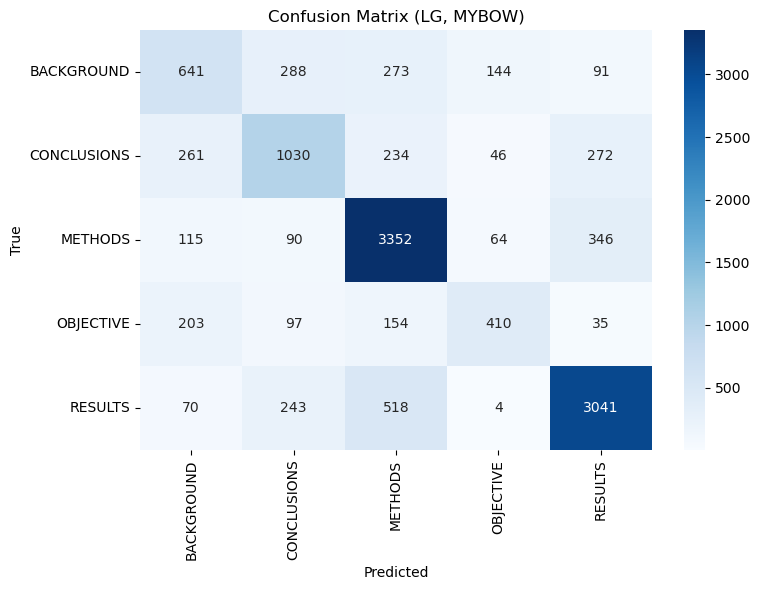

Pipeline(steps=[('vectorizer',
                 CountVectorizer(max_features=500,
                                 preprocessor=<function clean_text at 0x301c95120>,
                                 stop_words='english',
                                 tokenizer=<function smart_tokenizer at 0x301c95a80>)),
                ('classifier', LogisticRegression(max_iter=1000))])

In [572]:
run_pipeline(train_subset, test_subset,model='lg',vector='mybow')

Using model: lg, vectorizer: bow


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Accuracy: 0.7629346198635835

 Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.57      0.59      0.58      1437
 CONCLUSIONS       0.69      0.66      0.67      1843
     METHODS       0.80      0.88      0.84      3967
   OBJECTIVE       0.67      0.51      0.58       899
     RESULTS       0.86      0.81      0.83      3876

    accuracy                           0.76     12022
   macro avg       0.71      0.69      0.70     12022
weighted avg       0.76      0.76      0.76     12022



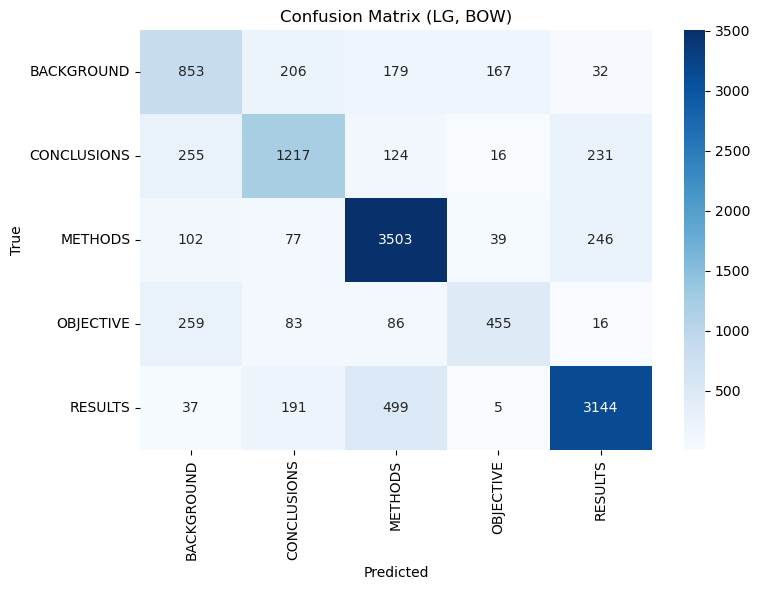

Pipeline(steps=[('vectorizer',
                 CountVectorizer(max_features=500,
                                 tokenizer=<function word_tokenize at 0x173edcea0>)),
                ('classifier', LogisticRegression(max_iter=1000))])

In [573]:
run_pipeline(train_subset, test_subset,model='lg',vector='bow')

Using model: lg, vectorizer: mybow3


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Accuracy: 0.7165197138579271

 Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.52      0.45      0.48      1437
 CONCLUSIONS       0.60      0.60      0.60      1843
     METHODS       0.74      0.85      0.79      3967
   OBJECTIVE       0.62      0.47      0.53       899
     RESULTS       0.83      0.79      0.81      3876

    accuracy                           0.72     12022
   macro avg       0.66      0.63      0.64     12022
weighted avg       0.71      0.72      0.71     12022



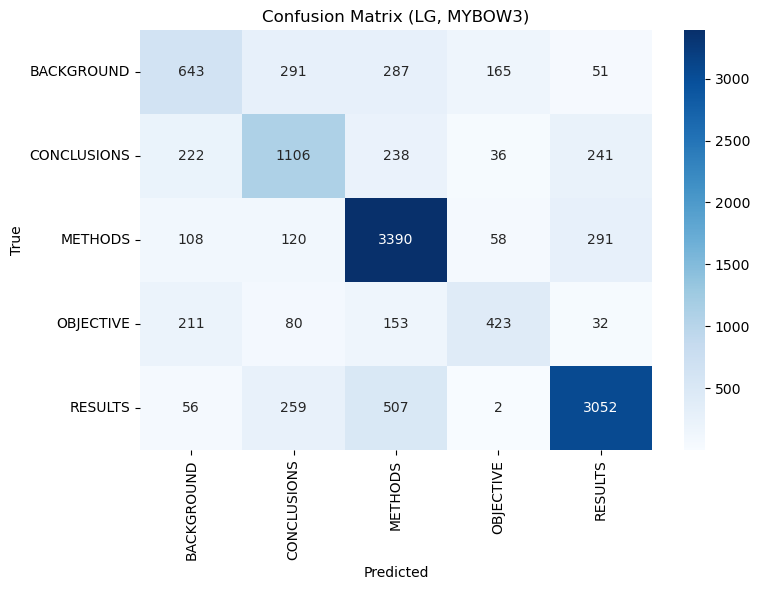

Pipeline(steps=[('vectorizer',
                 CountVectorizer(max_features=500,
                                 preprocessor=<function clean_text3 at 0x30f2f7b00>,
                                 stop_words='english',
                                 tokenizer=<function smart_tokenizer at 0x301c95a80>)),
                ('classifier', LogisticRegression(max_iter=1000))])

In [574]:
run_pipeline(train_subset, test_subset,model='lg',vector='mybow3')

In [575]:
# just want to see whether the good performance of the simplist representation is just good luck!!
# why????
run_pipeline(train_subset, test_subset,model='lg',vector='bow',cv=5) # using cv is much slower

Using model: lg, vectorizer: bow
Running 5-fold cross validation...


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packa

F1 macro scores: [0.69591835 0.68521992 0.68502891 0.68312554 0.69524573]
Mean F1: 0.6889076933444097
Accuracy scores: [0.76257914 0.75283239 0.75124958 0.74956261 0.76422561]
Mean accuracy: 0.756089866514822


__________________________________________________________

Fine, sometimes to be simple is better

__________________________________________________________

In [589]:
# svm
run_pipeline(train_subset, test_subset,model='svm',vector='mybow',cv=5) # it's slow

Using model: svm, vectorizer: mybow
Running 5-fold cross validation...


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packa

F1 macro scores: [0.61246065 0.60905496 0.60853296 0.60307967 0.61896398]
Mean F1: 0.6104184419857075
Accuracy scores: [0.70009997 0.69301899 0.69276908 0.68716154 0.70407398]
Mean accuracy: 0.6954247123546227


In [594]:
# rf
run_pipeline(train_subset, test_subset,model='rf',vector='mybow',cv=5) # slow slow
# I don't want to run it again anymore

Using model: rf, vectorizer: mybow
Running 5-fold cross validation...


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packa

F1 macro scores: [0.59672181 0.60376305 0.5967589  0.60064915 0.61065552]
Mean F1: 0.6017096842141656
Accuracy scores: [0.68218927 0.68552149 0.68018994 0.68424561 0.69124386]
Mean accuracy: 0.6846780321469671


Using model: rf, vectorizer: bow


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Accuracy: 0.768424554982532

 Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.63      0.58      0.60      1437
 CONCLUSIONS       0.68      0.66      0.67      1843
     METHODS       0.79      0.89      0.84      3967
   OBJECTIVE       0.67      0.49      0.57       899
     RESULTS       0.85      0.83      0.84      3876

    accuracy                           0.77     12022
   macro avg       0.72      0.69      0.70     12022
weighted avg       0.76      0.77      0.76     12022



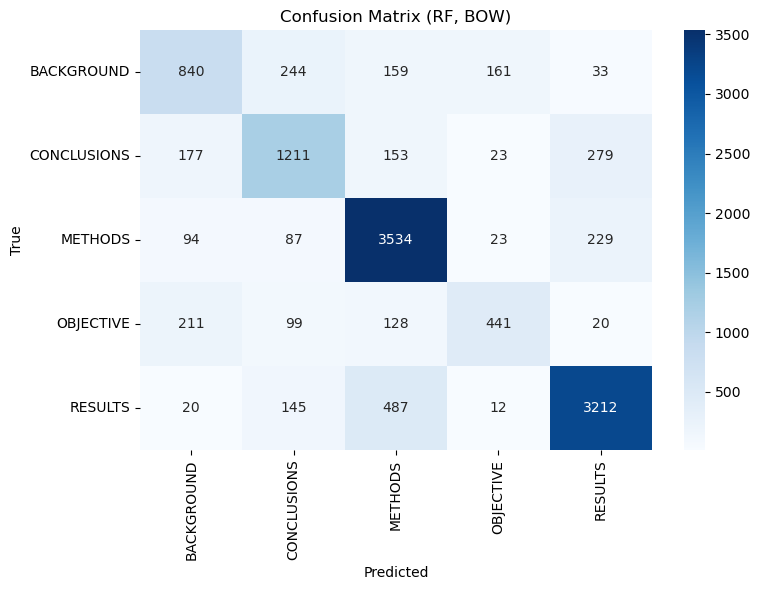

Pipeline(steps=[('vectorizer',
                 CountVectorizer(max_features=500,
                                 tokenizer=<function word_tokenize at 0x173edcea0>)),
                ('classifier', RandomForestClassifier(random_state=42))])

In [619]:
# rf
run_pipeline(train_subset, test_subset,model='rf',vector='bow') 

### time for tfidf

Using model: lg, vectorizer: tfidf


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Accuracy: 0.7690900016636167

 Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.60      0.53      0.56      1437
 CONCLUSIONS       0.68      0.70      0.69      1843
     METHODS       0.80      0.90      0.85      3967
   OBJECTIVE       0.63      0.47      0.54       899
     RESULTS       0.86      0.83      0.84      3876

    accuracy                           0.77     12022
   macro avg       0.71      0.69      0.70     12022
weighted avg       0.76      0.77      0.76     12022



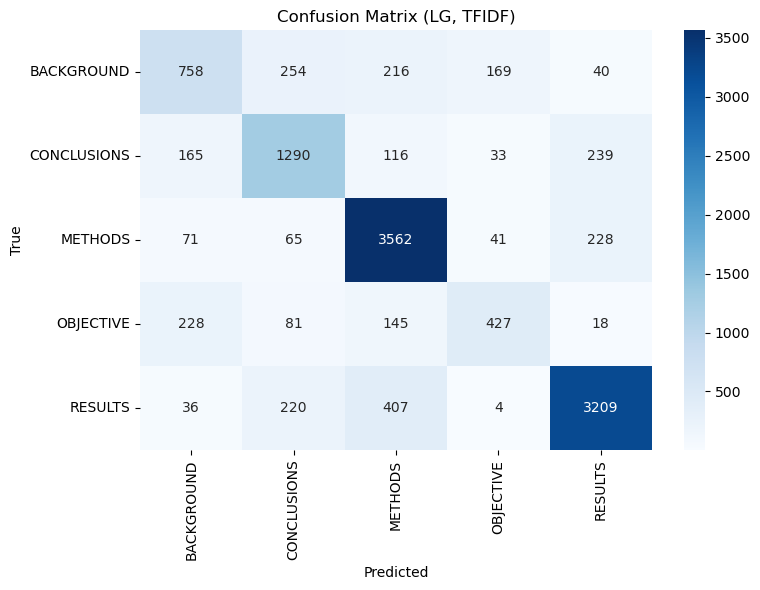

Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(stop_words='english',
                                 tokenizer=<function word_tokenize at 0x173edcea0>)),
                ('classifier', LogisticRegression(max_iter=1000))])

In [617]:
run_pipeline(train_subset, test_subset,model='lg',vector='tfidf')

Using model: rf, vectorizer: tfidf


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:521: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Accuracy: 0.7402262518715688

 Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.65      0.40      0.50      1437
 CONCLUSIONS       0.64      0.62      0.63      1843
     METHODS       0.73      0.92      0.81      3967
   OBJECTIVE       0.72      0.41      0.52       899
     RESULTS       0.83      0.82      0.82      3876

    accuracy                           0.74     12022
   macro avg       0.71      0.63      0.66     12022
weighted avg       0.74      0.74      0.73     12022



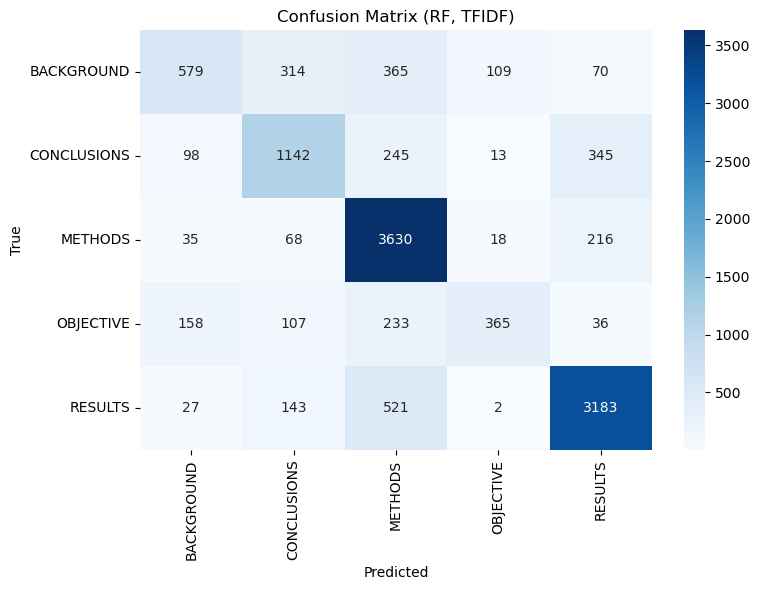

Pipeline(steps=[('vectorizer',
                 TfidfVectorizer(stop_words='english',
                                 tokenizer=<function word_tokenize at 0x173edcea0>)),
                ('classifier', RandomForestClassifier(random_state=42))])

In [361]:
run_pipeline(train_subset, test_subset,model='rf',vector='tfidf') # cv is tooooo slow

## Complex model: BERT+LSTM

In [371]:
# this cell is just copied from practicals just for possible using
# The Hugging Face sequence classifier - this is what we will
# load BERT Base in to, and which we will fine-tune
from transformers import AutoModelForSequenceClassification

# Many pre-trained transformer models have their own
# specific tokenisation. There is also a class to assist with
# padding, and to collate data for faster training
from transformers import AutoTokenizer, DataCollatorWithPadding

# Hugging Face has special classes to hold training arguments
# and to train the model
from transformers import TrainingArguments, Trainer

# We can use a Hugging Face pipeline to construct an end-to-end
# classifier from a model, that takes text as input and
# outputs the class
from transformers import pipeline

# The Hugging Face evaluation package
import evaluate

In [383]:
# 1000 abstracts for subset
sampled_pmid3 = stratified_sample_pmids(length_to_pmids, target_total=1000)
train_bert = trainingdata[trainingdata['pmid'].isin(sampled_pmid3)]
train_bert['pmid'].nunique()

1000

In [387]:
# group data by abstract using pmid to construct a structured representation
# each abstract is represented as lists of sentences and labels

# to save new structured data
abstracts = []

for pmid, group in train_bert.groupby("pmid"):
    sentence_list = group["text"].tolist()
    label_list = group["label"].tolist()
    abstracts.append({
        "pmid": pmid,
        "sentences": sentence_list,
        "labels": label_list
    })

# after processing
print(abstracts[0])

{'pmid': 24219882, 'sentences': ['We assessed the impact of hot flashes and various forms of hormone therapy on health-related quality of life and sexual well-being in recently postmenopausal women .', "We prospectively interviewed 150 healthy women about hot flashes and health-related quality of life ( using the Women 's Health Questionnaire and the McCoy Female Sexuality Questionnaire ) , menopause-related symptoms , and general health .", 'The women were classified into those with ( n = 72 ) and without ( n = 78 ) hot flashes and treated for 6 months with transdermal estradiol ( 1 mg/d ) , oral estradiol ( 2 mg/d ) with or without medroxyprogesterone acetate ( 5 mg/d ) , or placebo .', 'At baseline , hot flashes contributed most strongly to poor sleep ( correlation coefficient r = -0.525 , P < 0.0001 ) , somatic symptoms such as muscle pains ( r = -0.348 , P < 0.0001 ) , menstrual cycle-resembling complaints ( r = -0.304 , P < 0.0001 ) , anxiety and fears ( r = -0.283 , P < 0.0001 )

In [389]:
# bert tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

In [393]:
from transformers import AutoModel
bert_model = AutoModel.from_pretrained("bert-base-cased")

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

In [608]:
def get_bert_cls_vector(sentence):
    # tokenize the input sentence for BERT
    inputs = tokenizer(sentence, return_tensors="pt", truncation=True, padding=True)

    # pass through the BERT model
    with torch.no_grad():
        outputs = bert_model(**inputs)
    
    # extract the [CLS] token vector from the last hidden state
    # shape of last_hidden_state: (batch_size, seq_length, hidden_size)
    cls_vector = outputs.last_hidden_state[:, 0, :]  # shape: (1, hidden_size)
    return cls_vector.squeeze(0)  # shape: (hidden_size,)


In [610]:
from sklearn.preprocessing import LabelEncoder

# convert string labels to integers
label_encoder = LabelEncoder()

# flatten all labels 
all_labels = [label for abs in abstracts for label in abs["labels"]]
label_encoder.fit(all_labels)

# function to convert an abstract to BERT vector representations and encoded labels
def process_abstract(abstract):
    sentence_vecs = [get_bert_cls_vector(sent) for sent in abstract["sentences"]]
    label_ids = label_encoder.transform(abstract["labels"])
    return {
        "vectors": torch.stack(sentence_vecs),  # shape: (num_sents, hidden_size)
        "labels": torch.tensor(label_ids)       # shape: (num_sents,)
    }


In [445]:
import torch
# has been test for 100 and 500
abstract_batch = abstracts[:500]
#dataset = [process_abstract(abs) for abs in abstract_batch]

# for total 1000 abstacts (!very slow !)
dataset = [process_abstract(abs) for abs in abstracts]

# shape
print("shape：", dataset[0]["vectors"].shape)
print("label", dataset[0]["labels"])

shape： torch.Size([10, 768])
label tensor([3, 2, 2, 4, 4, 4, 4, 1, 1, 1])


In [447]:
from torch.utils.data import Dataset

# to store the sentence-level BERT embeddings and corresponding labels
class SentenceDataset(Dataset):
    def __init__(self, abstract_list):
        self.abstracts = abstract_list  # {"vectors": Tensor[n,768], "labels": Tensor[n]}
    
    # return the number of abstracts in the dataset
    def __len__(self):
        return len(self.abstracts
        
    # return the (vector, label) pair
    def __getitem__(self, idx):
        return self.abstracts[idx]


In [449]:
train_dataset = SentenceDataset(dataset)  # input training dataset for LSTM

In [451]:
import torch
from torch.nn.utils.rnn import pad_sequence

# batch is a list of dicts, each with:
# vectors: Tensor of shape (num_sents, 768)
# labels: Tensor of shape (num_sents,)

def collate_fn(batch):
    # list of input and label tensors
    inputs = [item["vectors"] for item in batch]
    labels = [item["labels"] for item in batch]

    # pad input tensors by sentence dimension to the same length (max abstract length)
    padded_inputs = pad_sequence(inputs, batch_first=True)  # shape: (batch_size, max_len, 768)

    # pad label tensors with a special value -100
    padded_labels = pad_sequence(labels, batch_first=True, padding_value=-100)  # shape: (batch_size, max_len)

    return padded_inputs, padded_labels


In [453]:
from torch.utils.data import DataLoader

# get 8 abstracts each time
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=collate_fn
)


In [612]:
for batch in train_loader:
    x, y = batch
    print("input shape：", x.shape)
    print("label shape：", y.shape)  
    break

input shape： torch.Size([8, 17, 768])
label shape： torch.Size([8, 17])


In [457]:
import torch.nn as nn

# Bidirectional LSTM to capture contextual information in both directions
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=256, num_labels=5, dropout=0.1):
        super(BiLSTMClassifier, self).__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=True)
        
        self.dropout = nn.Dropout(dropout)# dropout layer to prevent overfitting
        self.classifier = nn.Linear(hidden_dim * 2, num_labels)  # final classification layer: maps 2*hidden_dim to num_labels

    def forward(self, x):
        # x shape: (batch_size, seq_len, 768)
        lstm_out, _ = self.lstm(x)  # shape: (batch_size, seq_len, hidden_dim*2)
        logits = self.classifier(self.dropout(lstm_out))  # shape: (batch_size, seq_len, num_labels)
        return logits

In [459]:
criterion = nn.CrossEntropyLoss(ignore_index=-100)

In [614]:
model = BiLSTMClassifier()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4)

### BERT+BiLSTM Tests

Sorry I copied the same process 3 times because I want to save all results

Subsets of 100,500,1000

In [441]:
from tqdm import tqdm

# finally train the model 
# first results for 100 abstracts
model.train()
for epoch in range(3):
    total_loss = 0
    for x_batch, y_batch in tqdm(train_loader):
        x_batch = x_batch.to(device)           # (B, L, 768)
        y_batch = y_batch.to(device)           # (B, L)

        optimizer.zero_grad()
        logits = model(x_batch)                # (B, L, num_labels)
        loss = criterion(logits.view(-1, logits.shape[-1]), y_batch.view(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} Loss: {total_loss:.4f}")


100%|███████████████████████████████████████████| 63/63 [00:00<00:00, 90.12it/s]


Epoch 1 Loss: 61.3846


100%|███████████████████████████████████████████| 63/63 [00:00<00:00, 94.94it/s]


Epoch 2 Loss: 30.9423


100%|███████████████████████████████████████████| 63/63 [00:00<00:00, 93.43it/s]

Epoch 3 Loss: 25.2131


In [423]:
# results of 100 abstracts
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, y_batch in train_loader:  
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(x_batch)  # shape: (B, L, num_labels)
        preds = torch.argmax(logits, dim=-1)  # shape: (B, L)

     
        for pred, label in zip(preds, y_batch):
            mask = label != -100
            all_preds.extend(pred[mask].cpu().numpy())
            all_labels.extend(label[mask].cpu().numpy())


from sklearn.preprocessing import LabelEncoder
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))


              precision    recall  f1-score   support

  BACKGROUND       0.77      0.57      0.65       156
 CONCLUSIONS       0.87      0.59      0.70       196
     METHODS       0.71      0.90      0.80       392
   OBJECTIVE       0.00      0.00      0.00        77
     RESULTS       0.75      0.90      0.82       376

    accuracy                           0.75      1197
   macro avg       0.62      0.59      0.59      1197
weighted avg       0.71      0.75      0.72      1197



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [443]:
# results of 500 abstracts
model.train()
for epoch in range(3):
    total_loss = 0
    for x_batch, y_batch in tqdm(train_loader):
        x_batch = x_batch.to(device)           # (B, L, 768)
        y_batch = y_batch.to(device)           # (B, L)

        optimizer.zero_grad()
        logits = model(x_batch)                # (B, L, num_labels)
        loss = criterion(logits.view(-1, logits.shape[-1]), y_batch.view(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} Loss: {total_loss:.4f}")


model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, y_batch in train_loader:  
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(x_batch)  # shape: (B, L, num_labels)
        preds = torch.argmax(logits, dim=-1)  # shape: (B, L)
        
        for pred, label in zip(preds, y_batch):

            mask = label != -100
            all_preds.extend(pred[mask].cpu().numpy())
            all_labels.extend(label[mask].cpu().numpy())


from sklearn.preprocessing import LabelEncoder
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))


              precision    recall  f1-score   support

  BACKGROUND       0.81      0.65      0.72       707
 CONCLUSIONS       0.89      0.91      0.90       944
     METHODS       0.89      0.94      0.91      1883
   OBJECTIVE       0.64      0.72      0.68       459
     RESULTS       0.92      0.90      0.91      1890

    accuracy                           0.87      5883
   macro avg       0.83      0.82      0.82      5883
weighted avg       0.87      0.87      0.87      5883



In [463]:
# totally same for 1000 abstracts
model.train()
for epoch in range(3):
    total_loss = 0
    for x_batch, y_batch in tqdm(train_loader):
        x_batch = x_batch.to(device)           # (B, L, 768)
        y_batch = y_batch.to(device)           # (B, L)

        optimizer.zero_grad()
        logits = model(x_batch)                # (B, L, num_labels)
        loss = criterion(logits.view(-1, logits.shape[-1]), y_batch.view(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1} Loss: {total_loss:.4f}")


100%|█████████████████████████████████████████| 125/125 [00:01<00:00, 84.37it/s]


Epoch 1 Loss: 93.6480


100%|█████████████████████████████████████████| 125/125 [00:01<00:00, 91.00it/s]


Epoch 2 Loss: 46.0808


100%|█████████████████████████████████████████| 125/125 [00:01<00:00, 97.17it/s]

Epoch 3 Loss: 39.5353


In [465]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for x_batch, y_batch in train_loader:  
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(x_batch)  
        preds = torch.argmax(logits, dim=-1) 

        for pred, label in zip(preds, y_batch):
            mask = label != -100
            all_preds.extend(pred[mask].cpu().numpy())
            all_labels.extend(label[mask].cpu().numpy())

from sklearn.preprocessing import LabelEncoder
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))


              precision    recall  f1-score   support

  BACKGROUND       0.79      0.83      0.81      1475
 CONCLUSIONS       0.91      0.93      0.92      1824
     METHODS       0.93      0.95      0.94      3955
   OBJECTIVE       0.75      0.61      0.67       890
     RESULTS       0.93      0.92      0.93      3841

    accuracy                           0.90     11985
   macro avg       0.86      0.85      0.85     11985
weighted avg       0.90      0.90      0.90     11985

